In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

MAU_NEN = ListedColormap(["lightcoral", "lightsteelblue"])


def ve_bien(ax, mo_hinh, X, y, tieu_de):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    luoi = np.c_[xx.ravel(), yy.ravel()]
    if hasattr(mo_hinh, "feature_names_in_"):
        luoi = pd.DataFrame(luoi, columns=mo_hinh.feature_names_in_)
    vung = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, vung, cmap=MAU_NEN, alpha=0.8)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="crimson", s=14, marker="^",
               edgecolors="white", linewidths=0.3)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="navy", s=14,
               edgecolors="white", linewidths=0.3)
    ax.set_title(tieu_de, fontsize=10, fontweight="bold")
    ax.grid(False)

In [8]:
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}


def kc(u, v):
    return np.sqrt(((u - v) ** 2).sum())


print("Khoang cach KHI CHUA chuan hoa")
print(f"  d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"  d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")
print()

df = pd.read_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on {dl[0]:.2f}  diem_giua_ky {dl[1]:.2f}  chi_tieu {dl[2]:.0f}")
print()

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"  d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"  d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f} diem {X2[i, 1]:4.1f} khoang cach {khoang[i]:.3f} -> {ket}")
so_qua = int(y[gan].sum())
print(f"Bo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

Khoang cach KHI CHUA chuan hoa
  d(A, B) =    102.2
  d(A, C) =   3000.0

Do lech chuan cua ba cot:
  gio_on 7.82  diem_giua_ky 2.09  chi_tieu 1692

Khoang cach SAU KHI chuan hoa
  d(A, B) = 3.85
  d(A, C) = 1.79

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5 diem  6.4 khoang cach 0.198 -> qua
  gio  12.5 diem  6.1 khoang cach 0.202 -> qua
  gio  14.0 diem  6.4 khoang cach 0.260 -> qua
  gio   9.5 diem  6.1 khoang cach 0.373 -> rot
  gio  10.5 diem  5.8 khoang cach 0.386 -> qua
Bo phieu: 4 qua, 1 rot
Du doan: qua mon


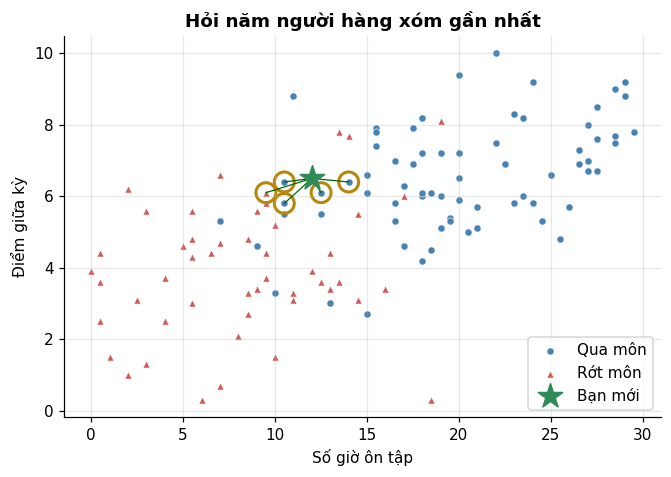

In [9]:
ig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X2[y == 1, 0], X2[y == 1, 1], c="steelblue", s=22, label="Qua môn",
           edgecolors="white", linewidths=0.4)
ax.scatter(X2[y == 0, 0], X2[y == 0, 1], c="indianred", marker="^", s=22,
           label="Rớt môn", edgecolors="white", linewidths=0.4)
ax.scatter(X2[gan, 0], X2[gan, 1], s=170, facecolors="none",
           edgecolors="darkgoldenrod", linewidths=2)
for i in gan:
    ax.plot([ban_moi[0], X2[i, 0]], [ban_moi[1], X2[i, 1]], c="darkgreen", lw=0.8)
ax.scatter(*ban_moi, marker="*", s=280, c="seagreen", label="Bạn mới", zorder=5)
ax.set_xlabel("Số giờ ôn tập")
ax.set_ylabel("Điểm giữa kỳ")
ax.set_title("Hỏi năm người hàng xóm gần nhất", fontweight="bold")
ax.legend(loc="lower right")
plt.show()

In [10]:
y3 = df["qua_mon"]
X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)


def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))


def knn_chuan():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))


ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


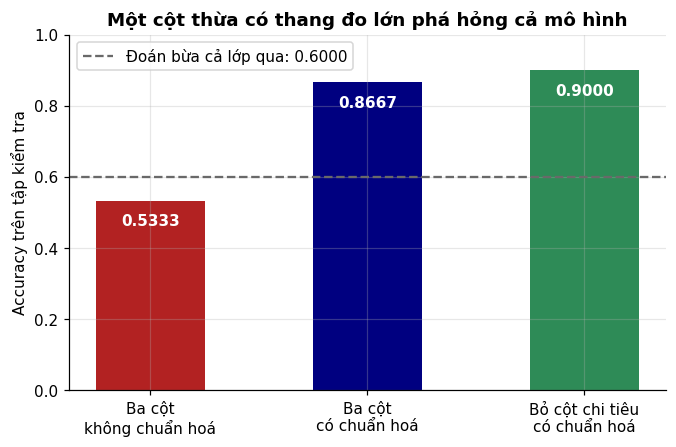

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
nhan = ["Ba cột\nkhông chuẩn hoá", "Ba cột\ncó chuẩn hoá", "Bỏ cột chi tiêu\ncó chuẩn hoá"]
cot = ax.bar(nhan, [a, b, c], color=["firebrick", "navy", "seagreen"], width=0.5)
for r, v in zip(cot, [a, b, c]):
    ax.text(r.get_x() + r.get_width() / 2, v - 0.07, f"{v:.4f}", ha="center",
            color="white", fontweight="bold")
ax.axhline(y_te.mean(), ls="--", c="dimgray", label=f"Đoán bừa cả lớp qua: {y_te.mean():.4f}")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy trên tập kiểm tra")
ax.set_title("Một cột thừa có thang đo lớn phá hỏng cả mô hình", fontweight="bold")
ax.legend(loc="upper left")
plt.show()

In [13]:
dm = pd.read_csv("hai_vang_trang.csv")
Xm = dm[["x1", "x2"]]
ym = dm["nhan"]
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    Xm, ym, test_size=0.25, random_state=17, stratify=ym
)

print("Accuracy tren tap hoc va tap kiem tra theo k")
print("  k   tap hoc  tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    a_hoc = accuracy_score(ym_tr, mh.predict(Xm_tr))
    a_kt = accuracy_score(ym_te, mh.predict(Xm_te))
    print(f" {k:3d}   {a_hoc:.4f}   {a_kt:.4f}")
print()

print("Kiem dinh cheo 5 phan tren tap hoc:")
diem_cv = {}
for k in range(1, 52, 2):
    diem_cv[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                                 Xm_tr, ym_tr, cv=5).mean()
k_tot = max(diem_cv, key=diem_cv.get)
for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem_cv[k]:.4f}{dau}")
print()

mh = KNeighborsClassifier(n_neighbors=k_tot).fit(Xm_tr, ym_tr)
print(f"k tot nhat (theo CV) = {k_tot}")
print(f"Accuracy tren tap kiem tra = {accuracy_score(ym_te, mh.predict(Xm_te)):.4f}")

Accuracy tren tap hoc va tap kiem tra theo k
  k   tap hoc  tap kiem tra
   1   1.0000   0.8000
   5   0.8756   0.9067
  13   0.8844   0.9200
  31   0.8667   0.8933
 101   0.8311   0.8533

Kiem dinh cheo 5 phan tren tap hoc:
  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667  <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat (theo CV) = 13
Accuracy tren tap kiem tra = 0.9200


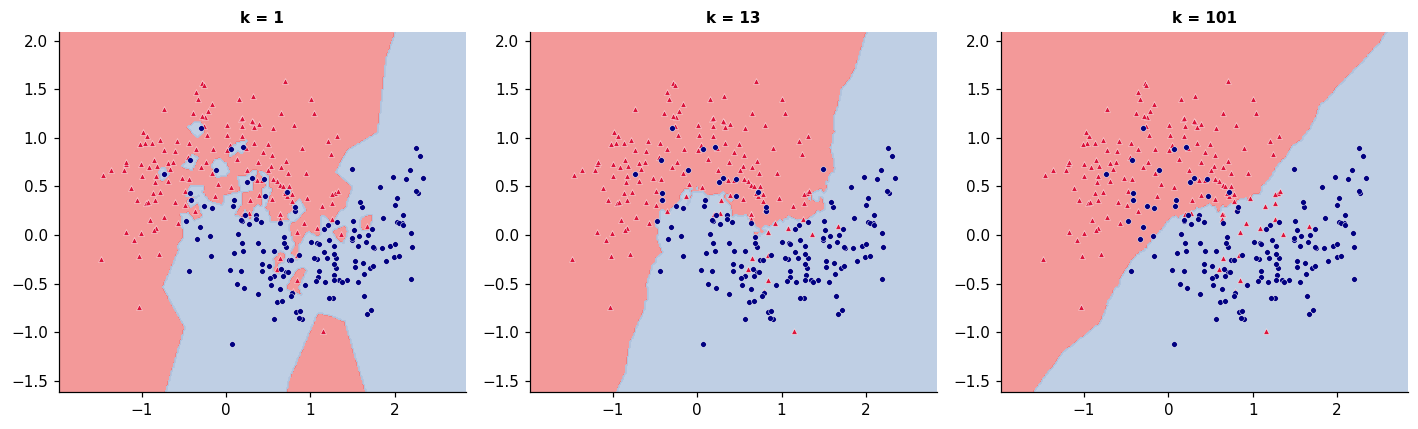

In [14]:
fig, truc = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(truc, [1, 13, 101]):
    mh = KNeighborsClassifier(n_neighbors=k).fit(Xm, ym)
    ve_bien(ax, mh, Xm, ym, f"k = {k}")
plt.tight_layout()
plt.show()

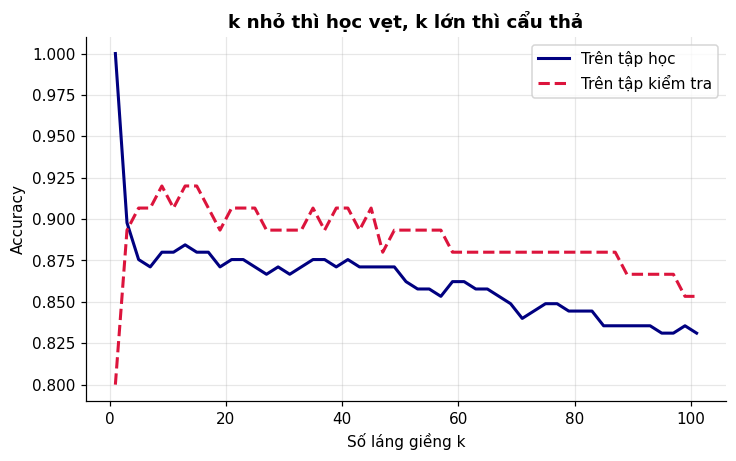

In [15]:
ks = list(range(1, 102, 2))
acc_hoc, acc_kt = [], []
for k in ks:
    mh = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    acc_hoc.append(accuracy_score(ym_tr, mh.predict(Xm_tr)))
    acc_kt.append(accuracy_score(ym_te, mh.predict(Xm_te)))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ks, acc_hoc, c="navy", lw=2, label="Trên tập học")
ax.plot(ks, acc_kt, c="crimson", lw=2, ls="--", label="Trên tập kiểm tra")
ax.set_xlabel("Số láng giềng k")
ax.set_ylabel("Accuracy")
ax.set_title("k nhỏ thì học vẹt, k lớn thì cẩu thả", fontweight="bold")
ax.legend()
plt.show()

In [16]:
cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(Xm_tr, ym_tr)
    print(f"  {ten}: {accuracy_score(ym_te, mh.predict(Xm_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang
  Hoi quy logistic: 0.8533
  Naive Bayes     : 0.8533
  KNN, k = 13     : 0.9200


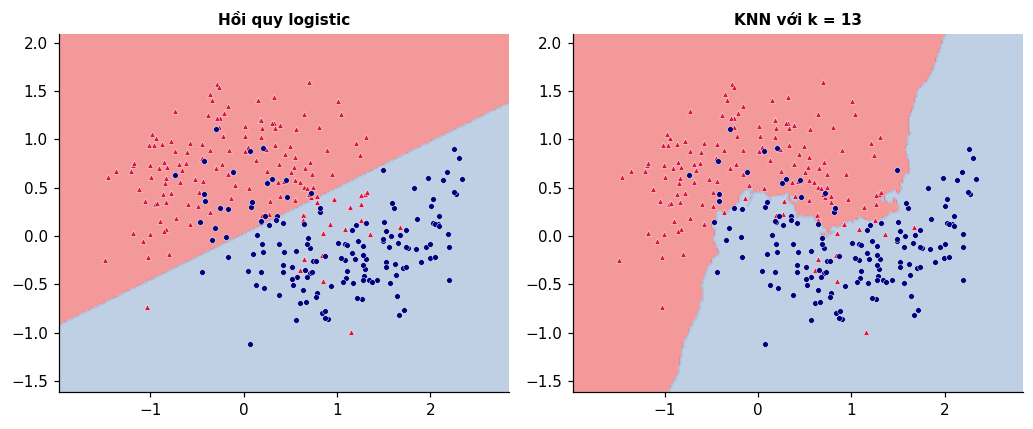

In [17]:
fig, truc = plt.subplots(1, 2, figsize=(9.5, 4))
ve_bien(truc[0], LogisticRegression().fit(Xm, ym), Xm, ym, "Hồi quy logistic")
ve_bien(truc[1], KNeighborsClassifier(13).fit(Xm, ym), Xm, ym, "KNN với k = 13")
plt.tight_layout()
plt.show()

    1 dac trung: ty so 0.001
    2 dac trung: ty so 0.028
    5 dac trung: ty so 0.134
   10 dac trung: ty so 0.303
   20 dac trung: ty so 0.464
   50 dac trung: ty so 0.627
  100 dac trung: ty so 0.693
  500 dac trung: ty so 0.860


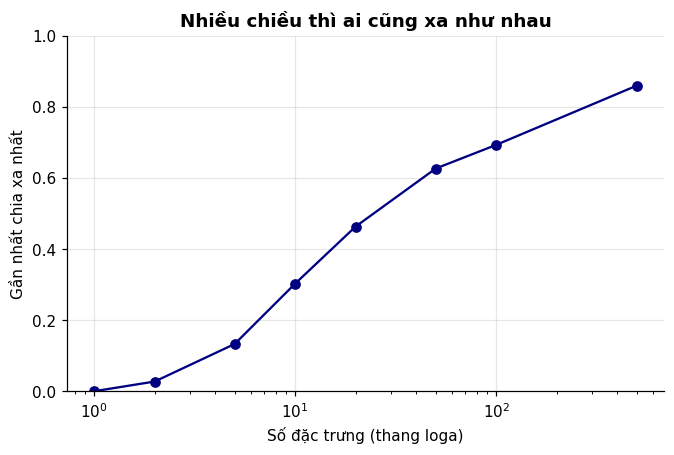

In [18]:
rng6 = np.random.default_rng(0)
so_chieu = [1, 2, 5, 10, 20, 50, 100, 500]
ty_so = []
for d in so_chieu:
    P = rng6.random((500, d))
    kc_6 = np.sqrt(((P[1:] - P[0]) ** 2).sum(axis=1))
    ty_so.append(kc_6.min() / kc_6.max())
    print(f"  {d:3d} dac trung: ty so {ty_so[-1]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(so_chieu, ty_so, "o-", c="navy")
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel("Số đặc trưng (thang loga)")
ax.set_ylabel("Gần nhất chia xa nhất")
ax.set_title("Nhiều chiều thì ai cũng xa như nhau", fontweight="bold")
plt.show()

In [20]:
dg = pd.read_csv("gia_nha.csv")
Xg = dg[["dien_tich"]]
yg = dg["gia"]
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.2, random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(Xg_tr, yg_tr)
duong = LinearRegression().fit(Xg_tr, yg_tr)

print("MAE tren tap kiem tra (ty dong)")
print(f"  KNN, k = 5 : {mean_absolute_error(yg_te, knn.predict(Xg_te)):.4f}")
print(f"  Duong thang: {mean_absolute_error(yg_te, duong.predict(Xg_te)):.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich   KNN   duong thang")
for dt, p, q in zip(can_moi["dien_tich"], knn.predict(can_moi), duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2 {p:6.2f} {q:6.2f}")
print()

_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = Xg_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

MAE tren tap kiem tra (ty dong)
  KNN, k = 5 : 0.4030
  Duong thang: 0.2578

Du doan cho bon can moi (ty dong)
  dien tich   KNN   duong thang
      60 m2   4.95   5.12
     100 m2   8.32   8.24
     150 m2   9.32  12.13
     250 m2   9.32  19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


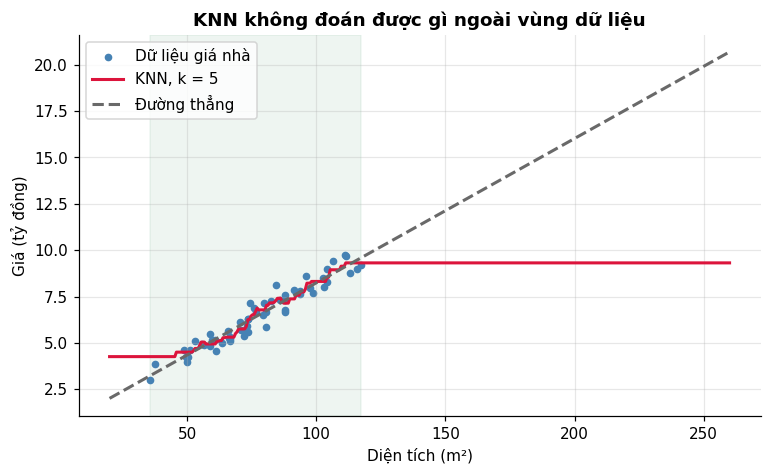

In [21]:
luoi = pd.DataFrame({"dien_tich": np.linspace(20, 260, 400)})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(dg["dien_tich"].min(), dg["dien_tich"].max(), color="seagreen", alpha=0.08)
ax.scatter(dg["dien_tich"], dg["gia"], s=16, c="steelblue", label="Dữ liệu giá nhà")
ax.plot(luoi["dien_tich"], knn.predict(luoi), c="crimson", lw=2, label="KNN, k = 5")
ax.plot(luoi["dien_tich"], duong.predict(luoi), c="dimgray", ls="--", lw=2,
        label="Đường thẳng")
ax.set_xlabel("Diện tích (m²)")
ax.set_ylabel("Giá (tỷ đồng)")
ax.set_title("KNN không đoán được gì ngoài vùng dữ liệu", fontweight="bold")
ax.legend(loc="upper left")
plt.show()

Accuracy KNN tu viet          : 0.9200
Accuracy KNeighborsClassifier : 0.9200
So mau du doan khac nhau: 0


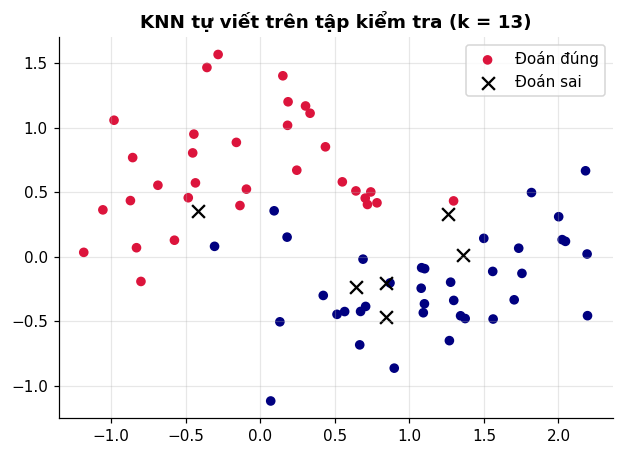

In [22]:
def knn_du_doan(X_hoc, y_hoc, x_moi, k):
    khoang = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))
    gan = np.argsort(khoang)[:k]
    nhan, dem = np.unique(y_hoc[gan], return_counts=True)
    return nhan[np.argmax(dem)]


Xh, yh = Xm_tr.to_numpy(float), ym_tr.to_numpy()
Xk = Xm_te.to_numpy(float)
dd_tu_viet = np.array([knn_du_doan(Xh, yh, x, 13) for x in Xk])
dd_sklearn = KNeighborsClassifier(n_neighbors=13).fit(Xm_tr, ym_tr).predict(Xm_te)

print(f"Accuracy KNN tu viet          : {accuracy_score(ym_te, dd_tu_viet):.4f}")
print(f"Accuracy KNeighborsClassifier : {accuracy_score(ym_te, dd_sklearn):.4f}")
print("So mau du doan khac nhau:", int((dd_tu_viet != dd_sklearn).sum()))

dung = dd_tu_viet == ym_te.to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(Xk[dung, 0], Xk[dung, 1], c=np.where(dd_tu_viet[dung] == 1, "navy", "crimson"),
           s=28, label="Đoán đúng")
ax.scatter(Xk[~dung, 0], Xk[~dung, 1], marker="x", c="black", s=70, label="Đoán sai")
ax.set_title("KNN tự viết trên tập kiểm tra (k = 13)", fontweight="bold")
ax.legend()
plt.show()

euclidean  k tot nhat 13  diem CV 0.8667  accuracy kiem tra 0.9200
manhattan  k tot nhat 27  diem CV 0.8667  accuracy kiem tra 0.9067


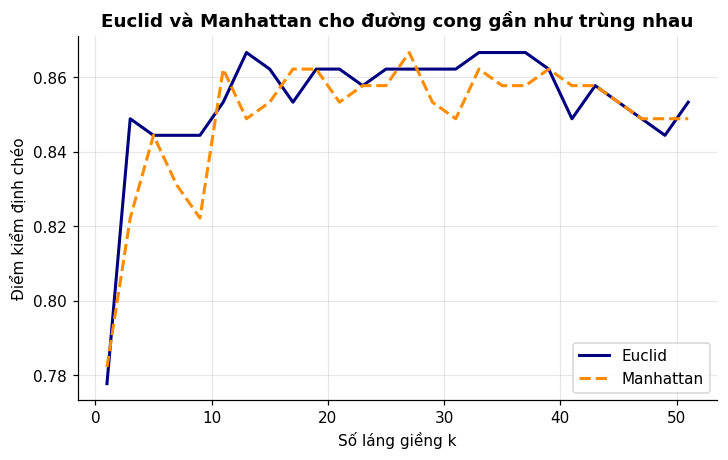

In [23]:
ket_qua_2 = {}
ks2 = list(range(1, 52, 2))
for metric in ["euclidean", "manhattan"]:
    d_cv = [cross_val_score(KNeighborsClassifier(n_neighbors=k, metric=metric),
                            Xm_tr, ym_tr, cv=5).mean() for k in ks2]
    k_t = ks2[int(np.argmax(d_cv))]
    mh = KNeighborsClassifier(n_neighbors=k_t, metric=metric).fit(Xm_tr, ym_tr)
    ket_qua_2[metric] = (d_cv, k_t, accuracy_score(ym_te, mh.predict(Xm_te)))
    print(f"{metric:10s} k tot nhat {k_t:2d}  diem CV {max(d_cv):.4f}  "
          f"accuracy kiem tra {ket_qua_2[metric][2]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ks2, ket_qua_2["euclidean"][0], c="navy", lw=2, label="Euclid")
ax.plot(ks2, ket_qua_2["manhattan"][0], c="darkorange", lw=2, ls="--", label="Manhattan")
ax.set_xlabel("Số láng giềng k")
ax.set_ylabel("Điểm kiểm định chéo")
ax.set_title("Euclid và Manhattan cho đường cong gần như trùng nhau", fontweight="bold")
ax.legend()
plt.show()

Không chuẩn hoá nghìn đồng             0.5333
Không chuẩn hoá triệu đồng             0.8667
Có chuẩn hoá nghìn đồng                0.8667
Có chuẩn hoá triệu đồng                0.8667


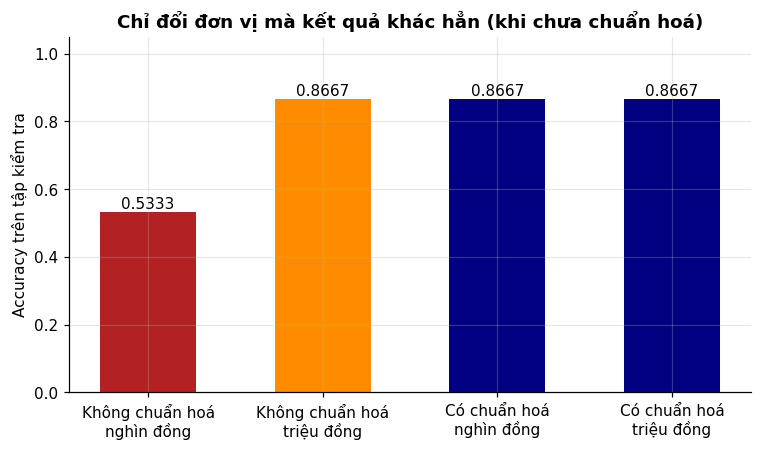

In [25]:
df = pd.read_csv("sinh_vien_mo_rong.csv")
y_sv = df["qua_mon"]
X_nghin = df[["gio_on", "diem_giua_ky", "chi_tieu"]].copy()
X_trieu = X_nghin.copy()
X_trieu["chi_tieu"] = X_trieu["chi_tieu"] / 1000


def danh_gia(X_, co_chuan_hoa):
    a_, b_, c_, d_ = train_test_split(X_, y_sv, test_size=0.25, random_state=17, stratify=y_sv)
    mh = (make_pipeline(StandardScaler(), KNeighborsClassifier(7)) if co_chuan_hoa
          else KNeighborsClassifier(n_neighbors=7))
    mh.fit(a_, c_)
    return accuracy_score(d_, mh.predict(b_))


kq3 = {
    "Không chuẩn hoá\nnghìn đồng": danh_gia(X_nghin, False),
    "Không chuẩn hoá\ntriệu đồng": danh_gia(X_trieu, False),
    "Có chuẩn hoá\nnghìn đồng": danh_gia(X_nghin, True),
    "Có chuẩn hoá\ntriệu đồng": danh_gia(X_trieu, True),
}
for ten, v in kq3.items():
    print(f"{ten.replace(chr(10), ' '):38s} {v:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
cot3 = ax.bar(list(kq3.keys()), list(kq3.values()),
              color=["firebrick", "darkorange", "navy", "navy"], width=0.55)
for r, v in zip(cot3, kq3.values()):
    ax.text(r.get_x() + r.get_width() / 2, v + 0.01, f"{v:.4f}", ha="center")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy trên tập kiểm tra")
ax.set_title("Chỉ đổi đơn vị mà kết quả khác hẳn (khi chưa chuẩn hoá)", fontweight="bold")
plt.show()

  k  uniform hoc  uniform kiem tra  distance hoc  distance kiem tra
  1       1.0000            0.8000           1.0             0.8000
 13       0.8844            0.9200           1.0             0.9333
101       0.8311            0.8533           1.0             0.9067


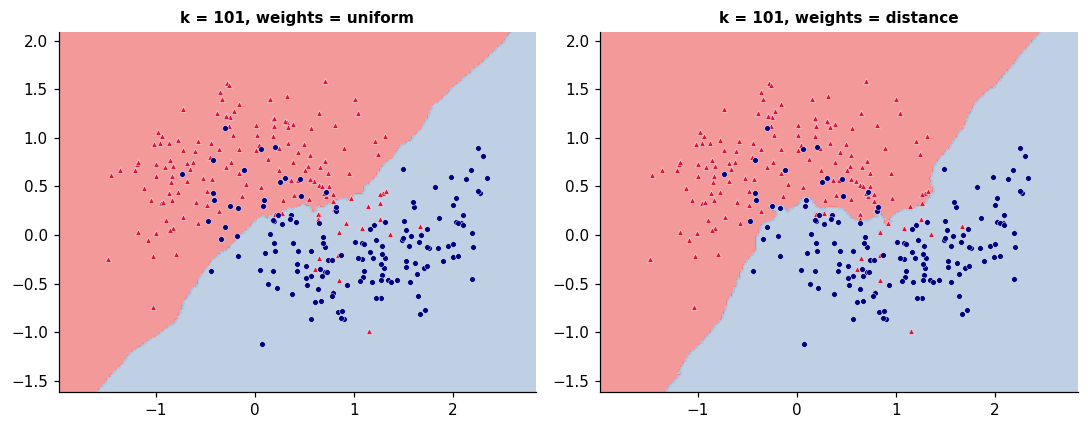

In [26]:
ks4 = [1, 13, 101]
bang4 = []
for k in ks4:
    dong = {"k": k}
    for w in ["uniform", "distance"]:
        mh = KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xm_tr, ym_tr)
        dong[w + " hoc"] = accuracy_score(ym_tr, mh.predict(Xm_tr))
        dong[w + " kiem tra"] = accuracy_score(ym_te, mh.predict(Xm_te))
    bang4.append(dong)
print(pd.DataFrame(bang4).round(4).to_string(index=False))

fig, truc = plt.subplots(1, 2, figsize=(10, 4))
for ax, w in zip(truc, ["uniform", "distance"]):
    mh = KNeighborsClassifier(n_neighbors=101, weights=w).fit(Xm, ym)
    ve_bien(ax, mh, Xm, ym, f"k = 101, weights = {w}")
plt.tight_layout()
plt.show()

k tot nhat = 2, MAE CV = 0.3498
MAE kiem tra KNN (k = 2) : 0.4867
MAE kiem tra duong thang  : 0.2578
KNN vuot duong thang: False


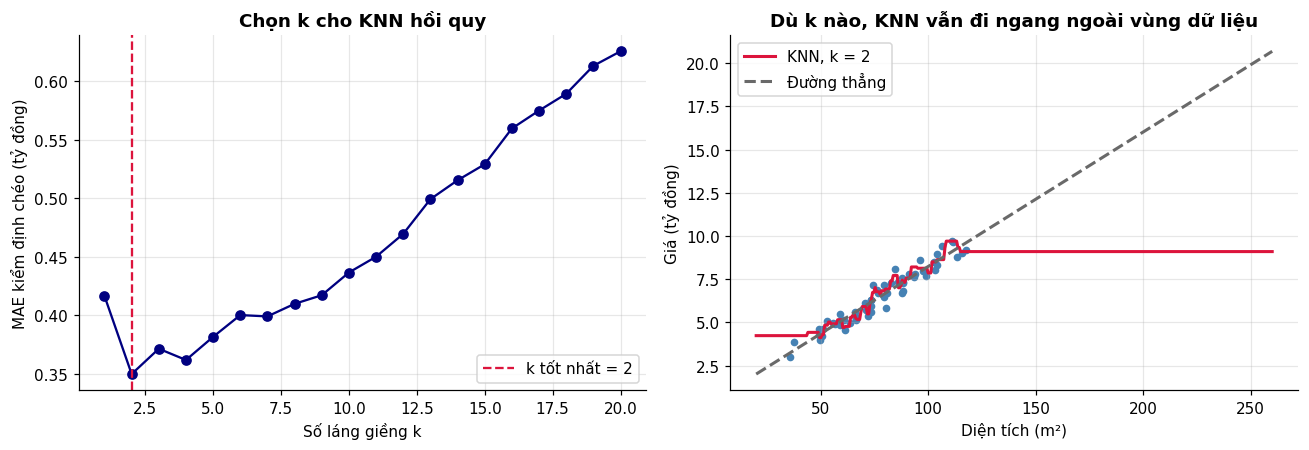

In [28]:
dg = pd.read_csv("gia_nha.csv")
Xg = dg[["dien_tich"]]
yg = dg["gia"]
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.2, random_state=42)
duong = LinearRegression().fit(Xg_tr, yg_tr)
luoi_g = pd.DataFrame({"dien_tich": np.linspace(20, 260, 400)})

ks5 = list(range(1, 21))
mae_cv = []
for k in ks5:
    d_ = cross_val_score(KNeighborsRegressor(n_neighbors=k), Xg_tr, yg_tr, cv=5,
                         scoring="neg_mean_absolute_error")
    mae_cv.append(-d_.mean())
k5 = ks5[int(np.argmin(mae_cv))]

knn5 = KNeighborsRegressor(n_neighbors=k5).fit(Xg_tr, yg_tr)
mae_knn5 = mean_absolute_error(yg_te, knn5.predict(Xg_te))
mae_dt = mean_absolute_error(yg_te, duong.predict(Xg_te))
print(f"k tot nhat = {k5}, MAE CV = {min(mae_cv):.4f}")
print(f"MAE kiem tra KNN (k = {k5}) : {mae_knn5:.4f}")
print(f"MAE kiem tra duong thang  : {mae_dt:.4f}")
print("KNN vuot duong thang:", mae_knn5 < mae_dt)

fig, truc = plt.subplots(1, 2, figsize=(12, 4.2))
truc[0].plot(ks5, mae_cv, "o-", c="navy")
truc[0].axvline(k5, c="crimson", ls="--", label=f"k tốt nhất = {k5}")
truc[0].set_xlabel("Số láng giềng k")
truc[0].set_ylabel("MAE kiểm định chéo (tỷ đồng)")
truc[0].set_title("Chọn k cho KNN hồi quy", fontweight="bold")
truc[0].legend()
truc[1].scatter(dg["dien_tich"], dg["gia"], s=16, c="steelblue")
truc[1].plot(luoi_g["dien_tich"], knn5.predict(luoi_g), c="crimson", lw=2, label=f"KNN, k = {k5}")
truc[1].plot(luoi_g["dien_tich"], duong.predict(luoi_g), c="dimgray", ls="--", lw=2, label="Đường thẳng")
truc[1].set_xlabel("Diện tích (m²)")
truc[1].set_ylabel("Giá (tỷ đồng)")
truc[1].set_title("Dù k nào, KNN vẫn đi ngang ngoài vùng dữ liệu", fontweight="bold")
truc[1].legend()
plt.tight_layout()
plt.show()

 so_mau  fit_giay  predict_giay
   1000   0.00444       0.00877
  10000   0.00128       0.05712
 100000   0.00861       0.63986


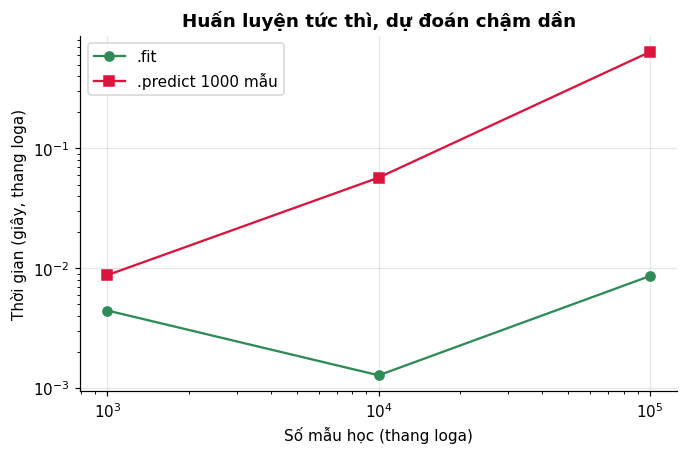

In [29]:
rng_t = np.random.default_rng(0)
X_moi = rng_t.random((1000, 2))
bang6 = []
for n_mau in [1000, 10000, 100000]:
    Xt = rng_t.random((n_mau, 2))
    yt = (Xt[:, 0] + Xt[:, 1] > 1).astype(int)
    mh = KNeighborsClassifier(n_neighbors=5, algorithm="brute")
    t0 = time.perf_counter()
    mh.fit(Xt, yt)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    mh.predict(X_moi)
    t_pred = time.perf_counter() - t0
    bang6.append({"so_mau": n_mau, "fit_giay": t_fit, "predict_giay": t_pred})
bang6 = pd.DataFrame(bang6)
print(bang6.to_string(index=False, float_format=lambda v: f"{v:.5f}"))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(bang6["so_mau"], bang6["fit_giay"], "o-", c="seagreen", label=".fit")
ax.plot(bang6["so_mau"], bang6["predict_giay"], "s-", c="crimson", label=".predict 1000 mẫu")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Số mẫu học (thang loga)")
ax.set_ylabel("Thời gian (giây, thang loga)")
ax.set_title("Huấn luyện tức thì, dự đoán chậm dần", fontweight="bold")
ax.legend()
plt.show()